In [1]:
!pip install -q ultralytics pyyaml

from ultralytics import YOLO
from pathlib import Path
import yaml
import glob
import os
import matplotlib.pyplot as plt
from PIL import Image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [2]:
yaml_files = glob.glob(
    "/kaggle/input/**/data.yaml",
    recursive=True
)

print("Found YAML files:")
for file in yaml_files:
    print(file)

if len(yaml_files) == 0:
    raise FileNotFoundError(
        "data.yaml not found. Add Notebook 1 output using Add Input."
    )

yaml_path = Path(yaml_files[0])
DATASET_PATH = yaml_path.parent

print("\nDataset path:", DATASET_PATH)

Found YAML files:
/kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/data.yaml

Dataset path: /kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10


In [3]:
with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

def find_images_folder(split, yaml_value):
    possible_names = {
        "train": ["train"],
        "val": ["valid", "val"],
        "test": ["test"]
    }

    if yaml_value:
        p = Path(yaml_value)

        candidates = [
            DATASET_PATH / p,
            yaml_path.parent / p
        ]

        for candidate in candidates:
            if candidate.exists():
                return candidate.resolve()

    # Search for the usual YOLO folder structure
    for images_folder in DATASET_PATH.rglob("images"):
        if images_folder.parent.name in possible_names[split]:
            return images_folder.resolve()

    raise FileNotFoundError(
        f"Could not find images folder for {split}"
    )


for split in ["train", "val", "test"]:
    if split in data:
        data[split] = str(
            find_images_folder(split, data[split])
        )

data["path"] = str(DATASET_PATH.resolve())

fixed_yaml = Path("/kaggle/working/data.yaml")

with open(fixed_yaml, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

print("Prepared dataset configuration:")
print(data)

Prepared dataset configuration:
{'train': '/kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/train/images', 'val': '/kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/valid/images', 'test': '/kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/test/images', 'nc': 3, 'names': ['head', 'helmet', 'person'], 'roboflow': {'workspace': 'joseph-nelson', 'project': 'hard-hat-workers', 'version': 10, 'license': 'Public Domain', 'url': 'https://universe.roboflow.com/joseph-nelson/hard-hat-workers/dataset/10'}, 'path': '/kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10'}


In [4]:
for split in ["train", "val", "test"]:
    if split in data:
        folder = Path(data[split])
        images = list(folder.glob("*"))

        print(f"{split}: {len(images)} images")

train: 4916 images
val: 1413 images
test: 706 images


In [5]:
model = YOLO("yolo11n.pt")

print("YOLO11n loaded successfully!")

YOLO11n loaded successfully!


In [6]:
results = model.train(
    data=str(fixed_yaml),
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    patience=10,
    project="/kaggle/working/runs/detect",
    name="hard_hat_detection",
    exist_ok=True
)

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hard_hat_detection, nbs=64, nms=None, opset=None, optimize=False

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      1.94G      1.321     0.8628      1.139         27        640: 100% ━━━━━━━━━━━━ 615/615 10.9it/s 56.4s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 89/89 11.3it/s 7.9s0.2s
                   all       1413       5353      0.934      0.576      0.622      0.396

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      1.94G      1.317     0.8541      1.141         17        640: 100% ━━━━━━━━━━━━ 615/615 11.0it/s 55.8s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 89/89 11.4it/s 7.8s0.2s
                   all       1413       5353      0.947      0.591      0.626        0.4

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      1.94G      1.295     0.8176      1.139         24        640: 100% ━━━━━━━━━━━━ 615/615 11.0it/s 56.0s0.2ss
                 Class   

In [7]:
best_model_path = Path(
    "/kaggle/working/runs/detect/hard_hat_detection/weights/best.pt"
)

if not best_model_path.exists():
    raise FileNotFoundError("best.pt was not created. Check training output.")

best_model = YOLO(str(best_model_path))

print("Best model loaded successfully!")

Best model loaded successfully!


In [8]:
if "test" in data:
    evaluation_split = "test"
else:
    evaluation_split = "val"

metrics = best_model.val(
    data=str(fixed_yaml),
    split=evaluation_split
)

print("Evaluation split:", evaluation_split)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 0.3±0.1 MB/s, size: 35.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/test/labels... 706 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 706/706 15.4it/s 45.9s0.1ss
WARNING ⚠️ val: Cache directory /kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 2.0it/s 22.0s0.2s
                   all        706       2705      0.964       0.63      0.658      0.461
                  head        140        726      0.943      0.943      0.961 


image 1/1 /kaggle/input/notebooks/nadafo/eda-01/Hard-Hat-Workers-10/test/images/005298_jpg.rf.a45f45b9d3abc292b3d0e53ff944adfc.jpg: 448x640 7 helmets, 8.1ms
Speed: 4.8ms preprocess, 8.1ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)


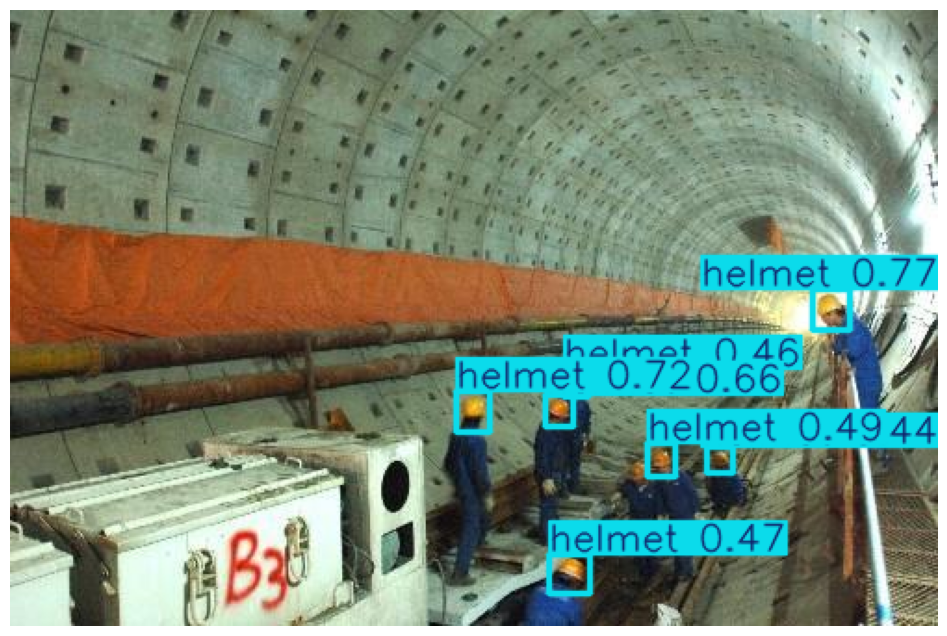

In [9]:
if "test" in data:
    image_folder = Path(data["test"])
else:
    image_folder = Path(data["val"])

image_files = [
    p for p in image_folder.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

if not image_files:
    raise FileNotFoundError("No images found for prediction.")

image_path = str(image_files[0])

prediction = best_model.predict(
    source=image_path,
    conf=0.25
)

result_image = prediction[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(result_image[:, :, ::-1])
plt.axis("off")
plt.show()

In [10]:
video_files = []

for ext in ["*.mp4", "*.avi", "*.mov", "*.mkv"]:
    video_files.extend(
        glob.glob(f"/kaggle/input/**/{ext}", recursive=True)
    )

print("Available videos:")

for video in video_files:
    print(video)

if len(video_files) == 0:
    raise FileNotFoundError(
        "No video found. Upload a video as a Kaggle Dataset "
        "and add it to this notebook using Add Input."
    )

Available videos:
/kaggle/input/datasets/nadafo/video-helmet/42923-434300950_medium.mp4


In [11]:
VIDEO_PATH = video_files[0]

print("Testing video:", VIDEO_PATH)

video_results = best_model.predict(
    source=VIDEO_PATH,
    conf=0.25,
    save=True,
    project="/kaggle/working",
    name="hard_hat_video_results",
    exist_ok=True
)

print("Video prediction completed!")

Testing video: /kaggle/input/datasets/nadafo/video-helmet/42923-434300950_medium.mp4

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/448) /kaggle/input/datasets/nadafo/video-helmet/42923-434300950_medium.mp4: 384x640 3 helmets, 49.0ms
video 1/1 (frame 2/448) /kaggle/input/datasets/nadafo/video-helmet/42923-434300950_medium.mp4: 384x640 3 helmets, 11.2ms
video 1/1 (frame 3/448) /kaggle/input/datasets/nadafo/video-helmet/42923-434300950_medium.mp4: 384x640 3 helmets, 8.7ms
video 1/1 (f

In [ ]:
from IPython.display import Video, display

output_folder = Path(
    "/kaggle/working/hard_hat_video_results"
)

output_videos = []

for ext in ["*.mp4", "*.avi", "*.mov", "*.mkv"]:
    output_videos.extend(output_folder.glob(ext))

if len(output_videos) == 0:
    print("Output video was not found. Check the prediction output.")
else:
    output_video = output_videos[0]

    print("Output video:", output_video)

    display(Video(str(output_video), embed=True))

Output video: /kaggle/working/hard_hat_video_results/42923-434300950_medium.avi


In [ ]:
import shutil

shutil.copy(
    best_model_path,
    "/kaggle/working/best_hard_hat_model.pt"
)

shutil.make_archive(
    "/kaggle/working/hard_hat_video_results",
    "zip",
    output_folder
)

print("Model and video results saved!")